# 미션 4_PyTorch 기초

텐서 조작부터 자동 미분, `nn.Module`, 학습 루프, 미니배치, 옵티마이저 비교까지 **PyTorch로 딥러닝 모델을 학습시키는 기본 흐름** 정리.

| 단계 | 내용 |
| :-- | :-- |
| **0. 준비** | 라이브러리 · 한글 폰트 · 그래프 설정, 난수 고정 |
| **1. 텐서 기초** | 생성 · 인덱싱 · 모양 변경 · 타입 변환 · 이어붙이기 · 행렬곱 · 자동 미분 · 활성화 함수 · device |
| **2. 모델 학습** | 손실 함수, 순수 autograd 선형 회귀, `nn.Module`, 2층 MLP, 학습 루프, DataLoader, 옵티마이저 · 학습률 비교 |
| **3. 마무리** | 옵티마이저 비교 서술, 최종 요약표 |

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표 (모든 문제는 `assert`로 정답 검증)

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 텐서의 모양 · 자료형 · 장치를 바꾸고, `cat`과 `stack` · `@`와 `*`의 차이를 결과로 설명한다
2. autograd가 계산한 기울기를 손 계산과 비교해 확인한다
3. 같은 선형 회귀를 순수 autograd와 `nn.Module` + 옵티마이저로 각각 구현한다
4. **기울기 초기화 → 순전파 → 손실 → 역전파 → 갱신** 5단계 학습 루프를 전체 배치 · 미니배치로 작성한다
5. 옵티마이저 · 학습률을 바꿔 수렴 속도 · 진동 · 죽은 ReLU를 측정값으로 비교한다

## 🧭 활용처

- **모든 딥러닝 학습 코드의 뼈대**: 이미지 · 텍스트 · 시계열 모델도 같은 5단계 루프와 DataLoader 사용
- **학습이 안 될 때 원인 찾기**: 손실 진동 · 발산은 학습률, 정확도 정체는 죽은 뉴런 · 모델 크기부터 점검
- **GPU · CPU 겸용 코드**: `device` 한 줄로 어느 환경에서나 같은 코드 실행

## 핵심 결과

- **자동 미분**: $y = x^2 + 3x$의 $x = 2$ 기울기 → autograd 7.0 = 손 계산 7
- **선형 회귀**: 순수 autograd · `nn.Module` 모두 w = 1.997 · b = 1.004 (정답 2 · 1) → 같은 직선
- **2층 MLP**: 파라미터 82개로 초승달 데이터 학습 정확도 98.0%, 미니배치 64는 **계산량 1/3**로 더 낮은 손실 (0.0586 vs 0.0670)
- **옵티마이저**: `Adam lr=0.01` 최종 손실 0.121 · 정확도 96.0%로 최고, `SGD lr=10.0`은 overshooting으로 진동 (정확도 70.4%, 죽은 ReLU 16개 중 9개)

---
## 0. 준비

### 0-1. 환경 설정

**한글 요약**

PyTorch · 시각화 · 데이터 생성 라이브러리를 불러오고, 한글 폰트와 그래프 격자 설정. 로그 축 눈금 함수 정의 후 난수를 고정하고 PyTorch 버전 · GPU 사용 가능 여부 확인.

**실행 흐름**

1. **입력**: 설치된 라이브러리 · 폰트
2. **처리**: 라이브러리 불러오기 → 한글 폰트 · 격자 설정 → 로그 축 눈금 함수 정의 → 난수 고정
3. **저장**: `plain_log` 함수
4. **출력**: PyTorch 버전 · CUDA 사용 가능 여부

In [1]:
# 라이브러리 불러오기
import matplotlib.pyplot as plt  # 그래프를 그리기 위해
import numpy as np  # 격자 좌표 · 손실 통계를 계산하기 위해
import pandas as pd  # 옵티마이저 비교 표를 만들기 위해
import torch  # 텐서 · 자동 미분을 쓰기 위해
import torch.nn as nn  # 층 · 손실 함수를 쓰기 위해
import torch.nn.functional as F  # 함수 형태 활성화(ReLU)를 쓰기 위해
from IPython.display import display  # 셀 중간에 표를 출력하기 위해
from matplotlib import font_manager  # 설치된 한글 폰트를 찾기 위해
from matplotlib.ticker import FuncFormatter, NullFormatter  # 로그 축 눈금을 일반 숫자로 보이기 위해
from sklearn.datasets import make_moons  # 직선으로 나눌 수 없는 분류 데이터를 만들기 위해
from torch.utils.data import DataLoader, TensorDataset  # 미니배치로 나누기 위해

# 그래프 스타일
installed = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트를 빠르게 찾기 위해
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 어디서든 한글이 보이도록
    if font in installed:  # 설치된 첫 한글 폰트를 쓰기 위해
        plt.rcParams["font.family"] = font  # 그래프 한글 깨짐을 막기 위해
        break  # 하나만 적용하기 위해
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않도록
plt.rcParams["axes.grid"] = True  # 값을 읽기 쉽도록 격자 표시
plt.rcParams["grid.alpha"] = 0.3  # 격자가 그래프를 가리지 않도록 옅게

# 로그 축 눈금 함수
def plain_log(ax):  # 손실 그래프마다 같은 설정을 반복하지 않도록
    """로그 축 눈금을 0.01 · 0.1 · 1처럼 일반 숫자로 표시"""
    ax.set_yscale("log")  # 손실이 수백 배 차이 나도 한 그래프에 보이도록
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))  # 10⁻² 대신 0.01처럼 읽기 쉽게
    ax.yaxis.set_minor_formatter(NullFormatter())  # 보조 눈금 글자가 겹치지 않도록

# 실행 환경 확인
torch.manual_seed(42)  # 난수 결과를 재현하기 위해
print("PyTorch", torch.__version__, "| CUDA 사용 가능:", torch.cuda.is_available())  # 버전 · GPU 사용 가능 여부를 확인하기 위해

PyTorch 2.11.0+cu128 | CUDA 사용 가능: True


**결과 해설**

```
PyTorch 2.11.0+cu128 : CUDA 12.8용 빌드
CUDA 사용 가능 True  : GPU 사용 가능 → 1-9에서 device 선택
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| plain_log() | 사용자 정의 함수 | 로그 축 + 일반 숫자 눈금 | `def plain_log(ax):` |
| manual_seed() · \_\_version\_\_ · cuda.is_available() | torch | 난수 고정 · 버전 · GPU 여부 | `torch.manual_seed(42)` |
| rcParams · set_yscale() · FuncFormatter() | matplotlib | 전역 설정 · 로그 축 · 눈금 변환 | `FuncFormatter(lambda v, _: f"{v:g}")` |
| print() | Python 내장 함수 | 버전 · GPU 여부 출력 | `print("PyTorch", torch.__version__, ...)` |
| import · for · def · lambda | Python 기본 문법 | 불러오기 · 폰트 탐색 · 함수 · 한 줄 함수 | `lambda v, _: f"{v:g}"` |

---
## 1. 텐서 기초

### 1-1. 텐서 생성

**한글 요약**

0~11 정수를 담은 **(3, 4) 크기 float32** 텐서 생성. 모양 · 자료형 · 첫 값 · 마지막 값으로 정답 검증.

**실행 흐름**

1. **입력**: 0~11 정수
2. **처리**: float32 연속 정수 생성 → (3, 4)로 모양 변경
3. **저장**: `t1`
4. **출력**: 텐서 값, 검증 결과

In [2]:
# 텐서 생성
t1 = torch.arange(12, dtype=torch.float32).reshape(3, 4)  # 실수 연산에 쓰도록 float32로 만든 뒤 3행 4열로 배치
print(t1)  # 값이 행 순서대로 채워졌는지 보기 위해

# 결과 검증
assert t1.shape == (3, 4) and t1.dtype == torch.float32 and t1[0, 0] == 0 and t1[2, 3] == 11  # 모양 · 자료형 · 처음 · 끝 값을 한 번에 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

tensor([[ 0.,  1.,  2.,  3.],
        [ 4.,  5.,  6.,  7.],
        [ 8.,  9., 10., 11.]])
✅ 통과


**결과 해설**

```
행마다 4개씩   : 0~3 / 4~7 / 8~11, 앞 행부터 순서대로 채움
0. · 1. 소수점 : float32 실수 자료형 표시
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| arange() · float32 | torch | 연속 정수 텐서 · 32비트 실수 | `torch.arange(12, dtype=torch.float32)` |
| reshape() · shape · dtype · [행, 열] | torch.Tensor | 모양 변경 · 크기 · 자료형 · 원소 | `t1[2, 3] == 11` |
| assert · and | Python 기본 문법 | 여러 조건 동시 검증 | `assert t1.shape == (3, 4) and ...` |

### 1-2. 인덱싱과 슬라이싱

**한글 요약**

(4, 5) 텐서에서 세 번째 행 · 마지막 열 · 1~2행 × 1~3열 부분 텐서 추출. 슬라이싱의 끝 인덱스는 **포함하지 않음** 확인.

**실행 흐름**

1. **입력**: 0~19로 만든 (4, 5) 텐서
2. **처리**: 행 · 열 · 부분 텐서 추출
3. **저장**: `row2` · `col_last` · `sub`
4. **출력**: 원본과 추출 결과, 검증 결과

In [3]:
# 텐서 준비
t2 = torch.arange(20).reshape(4, 5)  # 위치를 값으로 바로 알 수 있도록 0~19를 4행 5열로

# 인덱싱 · 슬라이싱
row2 = t2[2]  # 0부터 세므로 세 번째 행을 꺼내기 위해
col_last = t2[:, -1]  # 모든 행의 마지막 열을 꺼내기 위해
sub = t2[1:3, 1:4]  # 끝 인덱스가 빠지는지 보기 위해 → (2, 3)
print(t2, row2, col_last, sub, sep="\n")  # 원본과 추출 결과를 줄바꿈해 비교하기 위해

# 결과 검증
assert torch.equal(row2, torch.tensor([10, 11, 12, 13, 14]))  # 세 번째 행 값이 맞는지 확인하기 위해
assert torch.equal(col_last, torch.tensor([4, 9, 14, 19]))  # 마지막 열 값이 맞는지 확인하기 위해
assert sub.shape == (2, 3) and sub[0, 0] == 6 and sub[1, 2] == 13  # 부분 텐서 모양 · 모서리 값을 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

tensor([[ 0,  1,  2,  3,  4],
        [ 5,  6,  7,  8,  9],
        [10, 11, 12, 13, 14],
        [15, 16, 17, 18, 19]])
tensor([10, 11, 12, 13, 14])
tensor([ 4,  9, 14, 19])
tensor([[ 6,  7,  8],
        [11, 12, 13]])
✅ 통과


**결과 해설**

```
t2[2]        : [10, 11, 12, 13, 14], 0번부터 세므로 세 번째 행
t2[:, -1]    : [4, 9, 14, 19], -1 = 마지막 위치
t2[1:3, 1:4] : 1~2행 × 1~3열 → (2, 3), 끝 번호(3행 · 4열)는 제외
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| arange() · tensor() · equal() | torch | 연속 정수 · 기대값 텐서 · 완전 일치 | `torch.equal(row2, torch.tensor([...]))` |
| [i] · [:, -1] · [a:b, c:d] | torch.Tensor | 행 · 열 인덱싱 · 범위 슬라이싱 | `t2[1:3, 1:4]` |
| print(sep) | Python 내장 함수 | 여러 텐서 줄바꿈 출력 | `print(t2, row2, ..., sep="\n")` |

### 1-3. 모양 바꾸기: squeeze · unsqueeze · reshape

**한글 요약**

`(3, 1, 4)` 텐서에서 크기 1 차원 제거 `(3, 4)` → 맨 뒤 차원 추가 `(3, 4, 1)`, 같은 데이터를 `(2, 6)`으로 재배열. reshape 전후 원소 순서가 같은지 `flatten`으로 확인.

**실행 흐름**

1. **입력**: (3, 1, 4) 난수 텐서
2. **처리**: squeeze(1) → unsqueeze(-1) → reshape(2, 6)
3. **저장**: `a` · `b` · `c`
4. **출력**: 모양 변화, 검증 결과

In [4]:
# 텐서 준비
t3 = torch.randn(3, 1, 4)  # 크기 1 차원을 다루기 위해 가운데 차원이 1인 난수 텐서

# 모양 바꾸기
a = t3.squeeze(1)  # 쓸모없는 크기 1 차원을 지우기 위해
b = a.unsqueeze(-1)  # 모델 입력 모양에 맞출 때처럼 맨 뒤에 차원을 추가하기 위해
c = t3.reshape(2, 6)  # 원소 12개를 순서 그대로 다른 모양으로 배치하기 위해
print(t3.shape, "→", a.shape, b.shape, c.shape)  # 모양 변화를 한눈에 보기 위해

# 결과 검증
assert a.shape == (3, 4) and b.shape == (3, 4, 1) and c.shape == (2, 6)  # 목표 모양이 맞는지 확인하기 위해
assert torch.equal(c.flatten(), t3.flatten())  # reshape가 원소 순서를 바꾸지 않는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

torch.Size([3, 1, 4]) → torch.Size([3, 4]) torch.Size([3, 4, 1]) torch.Size([2, 6])
✅ 통과


**결과 해설**

```
(3, 1, 4) → (3, 4) : 크기 1 차원만 제거, 원소 12개 유지
(3, 4) → (3, 4, 1) : 차원만 추가, 값 변화 없음
(2, 6)             : 원소 12개 = 2 × 6이므로 재배열 가능
flatten 비교 통과  : reshape는 원소 순서 유지
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| randn() · equal() | torch | 난수 텐서 · 완전 일치 | `torch.randn(3, 1, 4)` |
| squeeze() · unsqueeze() · reshape() · flatten() | torch.Tensor | 차원 제거 · 추가 · 재배열 · 펼치기 | `t3.squeeze(1)` · `a.unsqueeze(-1)` |
| assert · and | Python 기본 문법 | 여러 조건 동시 검증 | `assert a.shape == (3, 4) and ...` |

### 1-4. 타입 변환

**한글 요약**

실수 텐서를 long(정수)으로 바꿨다가 다시 float32로 변환. long 변환은 **반올림이 아닌 버림(0 쪽)** 이며, 버린 소수점은 되돌릴 수 없음 확인.

**실행 흐름**

1. **입력**: 실수 텐서 [1.7, 2.3, 3.9]
2. **처리**: long() 정수 변환 → float() 실수 재변환
3. **저장**: `t4_long` · `t4_float`
4. **출력**: 값 · 자료형, 검증 결과

In [5]:
# 텐서 준비
t4 = torch.tensor([1.7, 2.3, 3.9])  # 반올림 · 버림 차이가 보이도록 소수점 있는 실수

# 타입 변환
t4_long = t4.long()  # 라벨처럼 정수가 필요할 때를 보기 위해 (1.7 → 1, 반올림 아닌 버림)
t4_float = t4_long.float()  # 다시 실수로 바꿔도 버린 소수점이 돌아오지 않음을 보기 위해
print(t4_long, t4_long.dtype, "|", t4_float, t4_float.dtype)  # 값과 자료형을 함께 비교하기 위해

# 결과 검증
assert t4_long.dtype == torch.int64 and torch.equal(t4_long, torch.tensor([1, 2, 3]))  # 버림 결과가 맞는지 확인하기 위해
assert t4_float.dtype == torch.float32  # 실수로 돌아왔는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

tensor([1, 2, 3]) torch.int64 | tensor([1., 2., 3.]) torch.float32
✅ 통과


**결과 해설**

```
[1, 2, 3] int64      : 3.9도 4가 아닌 3, 소수점 버림
[1., 2., 3.] float32 : 실수로 돌아와도 원래 값(1.7 · 2.3 · 3.9) 복원 안 됨
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| tensor() · equal() · int64 · float32 | torch | 텐서 생성 · 일치 · 자료형 | `torch.tensor([1.7, 2.3, 3.9])` |
| long() · float() · dtype | torch.Tensor | 정수 · 실수 변환 · 자료형 | `t4.long()` · `t4_long.float()` |
| assert | Python 기본 문법 | 버림 결과 검증 | `assert t4_long.dtype == torch.int64 and ...` |

### 1-5. 이어붙이기: cat과 stack

**한글 요약**

같은 모양 (2, 3) 텐서 두 개 이어붙이기. `cat`은 **기존 차원**을 따라 잇고, `stack`은 **새 차원**을 만들어 쌓는 차이 확인.

**실행 흐름**

1. **입력**: 1로 채운 (2, 3) · 0으로 채운 (2, 3)
2. **처리**: cat dim=0 · cat dim=1 · stack
3. **저장**: `cat0` · `cat1` · `stacked`
4. **출력**: 세 결과 모양, 검증 결과

In [6]:
# 텐서 준비
a5, b5 = torch.ones(2, 3), torch.zeros(2, 3)  # 이어붙인 뒤 어느 쪽인지 구분하기 위해 1 · 0으로 채움

# 이어붙이기
cat0 = torch.cat([a5, b5], dim=0)  # 행을 늘리기 위해 0번 차원으로 이어 붙임 → (4, 3)
cat1 = torch.cat([a5, b5], dim=1)  # 열을 늘리기 위해 1번 차원으로 이어 붙임 → (2, 6)
stacked = torch.stack([a5, b5])  # 배치처럼 새 차원으로 쌓기 위해 → (2, 2, 3)
print(cat0.shape, cat1.shape, stacked.shape)  # 세 결과의 모양을 비교하기 위해

# 결과 검증
assert cat0.shape == (4, 3) and cat1.shape == (2, 6) and stacked.shape == (2, 2, 3)  # 목표 모양이 맞는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

torch.Size([4, 3]) torch.Size([2, 6]) torch.Size([2, 2, 3])
✅ 통과


**결과 해설**

```
cat dim=0 → (4, 3) : 행 수만 증가, 차원 수 2 유지
cat dim=1 → (2, 6) : 열 수만 증가, 차원 수 2 유지
stack → (2, 2, 3)  : 차원 수 2 → 3, 쌓은 텐서 개수(2)가 새 차원 크기
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| ones() · zeros() · cat() · stack() | torch | 1 · 0 텐서 · 기존 차원 잇기 · 새 차원 쌓기 | `torch.cat([a5, b5], dim=0)` · `torch.stack([a5, b5])` |
| shape | torch.Tensor | 크기 확인 | `cat0.shape == (4, 3)` |
| assert · and | Python 기본 문법 | 여러 조건 동시 검증 | `assert cat0.shape == (4, 3) and ...` |

### 1-6. 행렬곱과 원소곱

**한글 요약**

`@` 행렬곱 `(2×3)·(3×4) → (2×4)`과 `*` 원소곱(같은 위치끼리 곱) 비교. 모두 1인 행렬을 곱하면 **각 행의 합**이 나오는 성질로 검증.

**실행 흐름**

1. **입력**: (2, 3) 행렬 · (3, 4) 1행렬 · (2, 3) 2행렬
2. **처리**: @ 행렬곱 → * 원소곱
3. **저장**: `mm` · `ew`
4. **출력**: 두 연산 결과, 검증 결과

In [7]:
# 행렬 준비
m1 = torch.tensor([[1., 2., 3.], [4., 5., 6.]])  # 결과를 손으로 확인하기 쉬운 (2, 3) 행렬
m2 = torch.ones(3, 4)  # 곱하면 행 합이 나오도록 모두 1인 (3, 4)
m3 = torch.full((2, 3), 2.)  # 원소곱 결과가 2배가 되도록 모두 2인 (2, 3)

# 행렬곱 · 원소곱
mm = m1 @ m2  # 앞 행렬 열 수 = 뒤 행렬 행 수일 때 가능한 행렬곱 → (2, 4)
ew = m1 * m3  # 같은 위치끼리 곱하는 원소곱과 비교하기 위해
print(mm, ew, sep="\n")  # 두 연산 결과를 비교하기 위해

# 결과 검증
assert mm.shape == (2, 4) and mm[0, 0] == 6 and mm[1, 0] == 15  # 행 합(1+2+3, 4+5+6)이 맞는지 확인하기 위해
assert torch.equal(ew, m1 * 2)  # 모든 원소가 2배인지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

tensor([[ 6.,  6.,  6.,  6.],
        [15., 15., 15., 15.]])
tensor([[ 2.,  4.,  6.],
        [ 8., 10., 12.]])
✅ 통과


**결과 해설**

```
mm 첫 행 6 · 둘째 행 15 : 1+2+3 = 6, 4+5+6 = 15 (1행렬과의 곱 = 행 합)
mm 모양 (2, 4)          : (2×3)·(3×4), 가운데 3이 맞아야 곱셈 가능
ew                      : 모든 원소 2배, 모양 (2, 3) 유지
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| tensor() · ones() · full() · equal() | torch | 텐서 생성 · 1 · 지정 값 · 일치 | `torch.full((2, 3), 2.)` |
| @ · * · shape | torch.Tensor | 행렬곱 · 원소곱 · 크기 | `m1 @ m2` · `m1 * m3` |
| assert · and | Python 기본 문법 | 여러 조건 동시 검증 | `assert mm.shape == (2, 4) and ...` |

### 1-7. 자동 미분(autograd)

**한글 요약**

$y = x^2 + 3x$의 $x = 2$에서의 기울기를 autograd로 계산하고, 손 계산 $\frac{dy}{dx} = 2x + 3 = 7$과 비교.

**실행 흐름**

1. **입력**: x = 2 (기울기 추적 켜기)
2. **처리**: y = x² + 3x 계산(연산 기록) → backward() 역전파
3. **저장**: `x.grad`
4. **출력**: autograd · 손 계산 기울기, 검증 결과

In [8]:
# 순전파
x = torch.tensor(2.0, requires_grad=True)  # 이 텐서에 대한 연산을 기록해 기울기를 구하기 위해
y = x ** 2 + 3 * x  # 역전파에 쓸 계산 그래프를 만들기 위해

# 역전파
y.backward()  # 기록된 연산을 거꾸로 따라가며 기울기를 계산하기 위해
grad = x.grad  # 계산된 dy/dx를 꺼내기 위해
print(f"autograd: {grad.item()} · 손 계산: {2 * 2 + 3}")  # 자동 · 수동 결과를 비교하기 위해

# 결과 검증
assert grad.item() == 7.0  # 2x + 3 = 7과 같은지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

autograd: 7.0 · 손 계산: 7
✅ 통과


**결과 해설**

```
autograd 7.0 = 손 계산 7 : 미분 공식을 직접 쓰지 않아도 기울기 자동 계산
requires_grad=True       : 이 설정이 있어야 연산 기록 · backward() 가능
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| tensor(requires_grad=True) | torch | 기울기 추적 텐서 | `torch.tensor(2.0, requires_grad=True)` |
| backward() · grad · item() | torch.Tensor | 역전파 · 기울기 · Python 숫자 | `y.backward()` · `x.grad` |
| assert | Python 기본 문법 | 기울기 7 검증 | `assert grad.item() == 7.0` |

### 1-8. 활성화 함수

**한글 요약**

- ReLU(음수 → 0) · Sigmoid(0~1) · Softmax(합이 1인 확률 분포) 출력값 확인
- -5~5 구간에서 ReLU · Sigmoid · Tanh 모양 그래프 비교

**실행 흐름**

1. **입력**: 입력값 5개 · logits 3개
2. **처리**: ReLU · Sigmoid · Softmax 계산 → -5~5 구간 세 함수 계산
3. **저장**: `relu_out` · `sig_out` · `probs`
4. **출력**: 세 함수 출력, 검증 결과, 함수 모양 그래프

tensor([0.0000, 0.0000, 0.0000, 0.5000, 2.0000])
tensor([0.1192, 0.3775, 0.5000, 0.6225, 0.8808])
tensor([0.0900, 0.2447, 0.6652])
✅ 통과


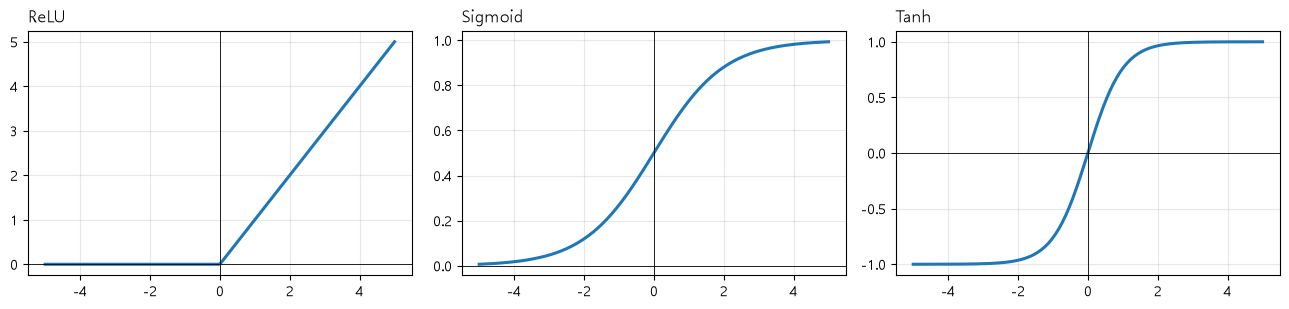

In [9]:
# 입력 준비
z = torch.tensor([-2.0, -0.5, 0.0, 0.5, 2.0])  # 음수 · 0 · 양수에서의 차이를 보기 위해
logits = torch.tensor([1.0, 2.0, 3.0])  # Softmax가 점수를 확률로 바꾸는지 보기 위해

# 활성화 함수
relu_out = torch.relu(z)  # 음수를 0으로 막는지 보기 위해
sig_out = torch.sigmoid(z)  # 0~1 사이로 압축하는지 보기 위해
probs = torch.softmax(logits, dim=0)  # 합이 1인 확률 분포가 되는지 보기 위해
print(relu_out, sig_out, probs, sep="\n")  # 세 함수의 출력을 비교하기 위해

# 결과 검증
assert torch.equal(relu_out, torch.tensor([0.0, 0.0, 0.0, 0.5, 2.0]))  # 음수 · 0만 0이 됐는지 확인하기 위해
assert abs(sig_out[2].item() - 0.5) < 1e-6 and abs(probs.sum().item() - 1.0) < 1e-6 and probs.argmax() == 2  # sigmoid(0) = 0.5, 확률 합 1, 최고 점수 위치를 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

# 함수 모양 그래프
zz = torch.linspace(-5, 5, 200)  # 곡선을 매끄럽게 그리기 위해 200개 입력
activations = {"ReLU": torch.relu(zz), "Sigmoid": torch.sigmoid(zz), "Tanh": torch.tanh(zz)}  # 이름과 출력을 짝지어 반복하기 위해
fig, axes = plt.subplots(1, 3, figsize=(13, 3.2))  # 세 함수를 나란히 비교하기 위해
for ax, (name, out) in zip(axes, activations.items()):  # 칸마다 함수 하나를 그리기 위해
    ax.plot(zz, out, linewidth=2.2)  # 함수 곡선을 그리기 위해
    ax.axhline(0, color="black", linewidth=0.6)  # 출력 0 위치를 보이기 위해
    ax.axvline(0, color="black", linewidth=0.6)  # 입력 0 위치를 보이기 위해
    ax.set_title(name, loc="left")  # 어떤 함수인지 알리기 위해
plt.tight_layout()  # 칸 간격을 자동으로 맞추기 위해
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
ReLU [0, 0, 0, 0.5, 2]     : 음수 · 0 → 0, 양수 그대로
Sigmoid(0) = 0.5           : 입력 0이 정확히 중간, ±2에서 0.1192 · 0.8808
Softmax [0.09, 0.24, 0.67] : 합 1, 점수 1점 차이마다 확률 약 2.72배(e배)
그래프                     : Sigmoid 0~1 · Tanh -1~1 범위, ReLU는 0 이하에서 평평
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| relu() · sigmoid() · tanh() · softmax() | torch | 활성화 함수 · 점수 → 확률 | `torch.softmax(logits, dim=0)` |
| linspace() · equal() | torch | 일정 간격 값 · 완전 일치 | `torch.linspace(-5, 5, 200)` |
| sum() · argmax() · item() | torch.Tensor | 합 · 최댓값 위치 · 숫자 | `probs.sum().item()` |
| subplots() · plot() · axhline() · axvline() | matplotlib | 그래프 칸 · 곡선 · 기준선 | `ax.plot(zz, out, ...)` |
| abs() · zip() | Python 내장 함수 | 오차 비교 · 칸과 함수 짝 | `abs(sig_out[2].item() - 0.5)` |

### 1-9. device 설정

**한글 요약**

GPU가 있으면 `cuda`, 없으면 `cpu`를 고르는 한 줄로 **어느 환경에서나 같은 코드 동작**. 텐서를 선택한 장치로 옮긴 뒤 위치 확인.

**실행 흐름**

1. **입력**: CPU에서 만든 (2, 2) 난수 텐서
2. **처리**: CUDA 사용 가능 여부로 cuda / cpu 선택 → to(device) 이동
3. **저장**: `device` · `t9_dev`
4. **출력**: 사용 중인 장치 이름, 검증 결과

In [10]:
# 텐서 준비
t9 = torch.randn(2, 2)  # 기본 생성 위치(CPU)에서 시작하기 위해

# device 선택 · 이동
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 없어도 같은 코드가 돌도록 CPU로 자동 대체
t9_dev = t9.to(device)  # 계산할 장치로 복사하기 위해
print("사용 중인 device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")  # 어떤 장치인지 확인하기 위해

# 결과 검증
assert device == ("cuda" if torch.cuda.is_available() else "cpu") and t9_dev.device.type == device  # 텐서가 선택한 장치에 있는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

사용 중인 device: cuda | NVIDIA GeForce RTX 3060
✅ 통과


**결과 해설**

```
cuda | NVIDIA GeForce RTX 3060 : GPU 사용 환경
to(device)                     : 원본 t9는 CPU에 그대로, 복사본만 GPU로 이동
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| randn() · cuda.is_available() · cuda.get_device_name() | torch | 난수 · GPU 여부 · GPU 이름 | `torch.cuda.get_device_name(0)` |
| to() · device.type | torch.Tensor | 장치로 복사 · 위치 확인 | `t9.to(device)` |
| 조건 표현식 · assert | Python 기본 문법 | GPU 있으면 cuda · 검증 | `"cuda" if torch.cuda.is_available() else "cpu"` |

---
## 2. 모델 학습

### 2-1. 손실 함수: 직접 계산 vs 내장 함수

**한글 요약**

- MSE(오차 제곱의 평균)를 직접 계산한 값과 `nn.MSELoss` 비교
- `CrossEntropyLoss`에는 **softmax 이전의 logits**와 **정수 라벨** 입력, 정답 클래스의 `-log(확률)` 평균과 같은지 확인

**실행 흐름**

1. **입력**: 회귀 예측 · 정답, 분류 logits · 라벨
2. **처리**: MSE 직접 · 내장 계산 → CrossEntropy 내장 · 직접 계산
3. **저장**: `mse_manual` · `mse_builtin` · `ce` · `ce_manual`
4. **출력**: 두 방식 손실, 검증 결과

In [11]:
# 데이터 준비
pred, target = torch.tensor([2.5, 0.0, 2.0]), torch.tensor([3.0, -0.5, 2.0])  # 손으로 계산하기 쉬운 회귀 예측 · 정답
logits2, labels = torch.tensor([[2.0, 0.5, 0.3], [0.2, 2.5, 0.1]]), torch.tensor([0, 1])  # CrossEntropy 입력 형식(점수 · 정수 라벨)을 보이기 위해

# MSE
mse_manual = ((pred - target) ** 2).mean()  # 정의대로 직접 계산하기 위해 (0.25 + 0.25 + 0) / 3 = 1/6
mse_builtin = nn.MSELoss()(pred, target)  # 내장 함수와 비교하기 위해 손실 객체를 만들어 바로 호출

# CrossEntropy
ce = nn.CrossEntropyLoss()(logits2, labels)  # softmax + log가 내부에 들어 있는지 보기 위해
ce_manual = -torch.log_softmax(logits2, dim=1)[torch.arange(2), labels].mean()  # 샘플별 정답 클래스의 -log(확률) 평균을 직접 구하기 위해
print(f"MSE 직접 {mse_manual:.4f} · 내장 {mse_builtin:.4f} | CE 내장 {ce:.4f} · 직접 {ce_manual:.4f}")  # 직접 · 내장 결과를 비교하기 위해

# 결과 검증
assert torch.allclose(mse_manual, mse_builtin) and abs(mse_manual.item() - 1 / 6) < 1e-6  # MSE가 손 계산 1/6과 같은지 확인하기 위해
assert torch.allclose(ce, ce_manual) and ce.item() > 0  # CE 두 방식이 같은지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

MSE 직접 0.1667 · 내장 0.1667 | CE 내장 0.2577 · 직접 0.2577
✅ 통과


**결과 해설**

```
MSE 0.1667 : 직접 = 내장 = 1/6
CE 0.2577  : 직접 = 내장, 두 샘플 모두 정답 클래스 점수가 가장 높아 손실 작음
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| MSELoss() · CrossEntropyLoss() | torch.nn | 평균 제곱 오차 · 분류 손실 | `nn.CrossEntropyLoss()(logits2, labels)` |
| log_softmax() · arange() · allclose() | torch | softmax 후 log · 샘플 번호 · 근사 일치 | `torch.log_softmax(logits2, dim=1)` |
| mean() · item() · [행, 열] | torch.Tensor | 평균 · 숫자 · 정답 위치 값 | `[torch.arange(2), labels]` |
| abs() · print() | Python 내장 함수 | 오차 비교 · 출력 | `abs(mse_manual.item() - 1 / 6)` |

### 2-2. 순수 autograd로 선형 회귀

**한글 요약**

- `nn.Module` 없이 $y = 2x + 1$ (+ 노이즈) 데이터로 w · b 직접 학습
- 파라미터 갱신은 그래프에 기록되지 않도록 `torch.no_grad()` 안에서, 기울기는 매 단계 0으로 초기화

**실행 흐름**

1. **입력**: y = 2x + 1 + 노이즈 데이터 100개
2. **처리**: w 난수 · b 0 초기화 → 순전파 → 손실 → 역전파 → no_grad 안에서 경사 하강 → 기울기 초기화 (500번)
3. **저장**: `w` · `b` · `losses2`
4. **출력**: 학습된 w · b · 최종 손실, 검증 결과

In [12]:
# 데이터 준비
torch.manual_seed(42)  # 노이즈 · 초기값을 재현하기 위해
x2 = torch.linspace(0, 1, 100).unsqueeze(1)  # 모델 입력 모양 (100, 1)로 맞추기 위해
y2 = 2 * x2 + 1 + 0.05 * torch.randn(100, 1)  # 정답 직선을 알고 있는 데이터를 만들기 위해 작은 노이즈 추가

# 파라미터 준비
lr = 0.3  # 한 번에 이동하는 보폭을 정하기 위해
w = torch.randn(1, requires_grad=True)  # 기울기를 추적해 학습하기 위해
b = torch.zeros(1, requires_grad=True)  # 기울기를 추적해 학습하기 위해
losses2 = []  # 학습 과정을 그래프로 보기 위해 손실 기록

# 학습
for step in range(500):  # 충분히 수렴하도록 500번 반복
    y_hat = x2 * w + b  # 1) 순전파로 예측을 구하기 위해
    loss = ((y_hat - y2) ** 2).mean()  # 예측이 얼마나 틀렸는지 MSE로 재기 위해
    losses2.append(loss.item())  # 그래프에 쓰기 위해 숫자만 기록
    loss.backward()  # 2) 역전파로 w.grad · b.grad를 채우기 위해
    with torch.no_grad():  # 3) 갱신 자체가 계산 그래프에 기록되지 않도록
        w -= lr * w.grad  # 손실이 줄어드는 방향(기울기 반대)으로 이동하기 위해
        b -= lr * b.grad  # 편향도 같은 방식으로 갱신하기 위해
    w.grad.zero_()  # 4) 다음 단계에 기울기가 누적되지 않도록
    b.grad.zero_()  # 편향 기울기도 누적되지 않도록

# 결과 검증
print(f"학습된 w = {w.item():.3f} (정답 2) · b = {b.item():.3f} (정답 1) · 최종 손실 {losses2[-1]:.5f}")  # 정답 직선과 비교하기 위해
assert abs(w.item() - 2) < 0.2 and abs(b.item() - 1) < 0.2 and losses2[-1] < 0.02  # 정답 근처에 도달했는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

학습된 w = 1.997 (정답 2) · b = 1.004 (정답 1) · 최종 손실 0.00241
✅ 통과


**결과 해설**

```
w = 1.997 · b = 1.004 : 정답 2 · 1과 거의 일치
최종 손실 0.00241     : 노이즈 크기(0.05)의 제곱 0.0025 수준 → 노이즈만 남고 직선은 다 학습
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| manual_seed() · linspace() · randn() · zeros() · no_grad() | torch | 난수 고정 · 데이터 · 파라미터 · 기록 끄기 | `with torch.no_grad():` |
| unsqueeze() · backward() · grad · zero_() | torch.Tensor | (100,) → (100, 1) · 역전파 · 기울기 · 초기화 | `w.grad.zero_()` |
| range() · append() | Python 내장 함수 · list | 500번 반복 · 손실 기록 | `losses2.append(loss.item())` |
| for · with · -= | Python 기본 문법 | 반복 · 구간 설정 · 빼서 갱신 | `w -= lr * w.grad` |

### 2-3. `nn.Module`로 선형 회귀 · 학습

**한글 요약**

- 2-2와 같은 문제를 PyTorch 표준 방식(`nn.Linear` + `MSELoss` + `SGD`)으로 학습
- 파라미터 등록 · 갱신 · 기울기 초기화를 PyTorch가 대신 처리

**실행 흐름**

1. **입력**: 2-2의 `x2` · `y2`
2. **처리**: nn.Module 상속 클래스(nn.Linear(1, 1)) → 손실 함수 · 옵티마이저 → 5단계 학습 (500번)
3. **저장**: `model3`
4. **출력**: 학습된 파라미터 · 이름 · 모양, 검증 결과

In [13]:
# 모델 정의
class LinearRegression(nn.Module):  # PyTorch가 파라미터를 관리하도록 nn.Module 상속
    def __init__(self):  # 모델에 필요한 층을 만들기 위해
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        self.linear = nn.Linear(1, 1)  # 가중치 · 편향이 자동 등록되도록 층으로 정의
    def forward(self, x):  # model(x)로 호출할 때 실행되도록
        return self.linear(x)  # 입력을 선형 층에 통과시키기 위해

# 학습 준비
torch.manual_seed(42)  # 초기 가중치를 재현하기 위해
model3 = LinearRegression()  # 무작위 초기값으로 모델을 만들기 위해
criterion = nn.MSELoss()  # 2-2와 같은 손실을 쓰기 위해
optimizer = torch.optim.SGD(model3.parameters(), lr=0.3)  # 2-2와 같은 학습률로 비교하기 위해

# 학습
for epoch in range(500):  # 2-2와 같은 횟수로 비교하기 위해
    optimizer.zero_grad()  # 이전 기울기가 누적되지 않도록
    loss = criterion(model3(x2), y2)  # 순전파와 손실을 한 번에 계산하기 위해
    loss.backward()  # 기울기를 구하기 위해
    optimizer.step()  # 옵티마이저가 대신 경사 하강하도록

# 결과 검증
print(f"학습된 weight = {model3.linear.weight.item():.3f} · bias = {model3.linear.bias.item():.3f}")  # 2-2 결과와 비교하기 위해
for name, p in model3.named_parameters():  # 자동 등록된 파라미터를 확인하기 위해
    print(f"  {name:<14} {tuple(p.shape)}  {type(p).__name__}")  # 이름 · 모양 · 자료형을 보이기 위해
assert isinstance(model3.linear, nn.Linear)  # 층 종류가 맞는지 확인하기 위해
assert abs(model3.linear.weight.item() - 2) < 0.2 and abs(model3.linear.bias.item() - 1) < 0.2  # 정답 근처인지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

학습된 weight = 1.997 · bias = 1.004
  linear.weight  (1, 1)  Parameter
  linear.bias    (1,)  Parameter
✅ 통과


**결과 해설**

```
weight 1.997 · bias 1.004        : 2-2 순수 autograd와 같은 값
linear.weight (1, 1) · bias (1,) : nn.Linear가 Parameter로 자동 등록
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| LinearRegression | 사용자 정의 클래스 | nn.Linear 하나짜리 회귀 모델 | `model3 = LinearRegression()` |
| Module · Linear() · MSELoss() · named_parameters() | torch.nn | 부모 클래스 · 선형 층 · 손실 · 파라미터 | `nn.Linear(1, 1)` |
| SGD() · zero_grad() · step() | torch.optim | 경사 하강 · 기울기 초기화 · 갱신 | `torch.optim.SGD(model3.parameters(), lr=0.3)` |
| isinstance() · tuple() · type() | Python 내장 함수 | 자료형 확인 · 튜플 · 자료형 이름 | `type(p).__name__` |
| class · def · super() | Python 기본 문법 | 클래스 · 메서드 · 부모 초기화 | `super().__init__()` |

### 2-3. `nn.Module`로 선형 회귀 · 비교 그래프

**한글 요약**

2-2(순수 autograd)와 2-3(`nn.Module`)이 찾은 직선을 겹쳐 보고, 2-2의 손실 곡선을 로그 축으로 확인.

**실행 흐름**

1. **입력**: `x2` · `y2` · `w` · `b` · `model3` · `losses2`
2. **처리**: 두 방식 직선 계산(기울기 기록 없이) → 손실 곡선 로그 축
3. **저장**: 없음
4. **출력**: 두 방식 직선 · 손실 곡선 그래프

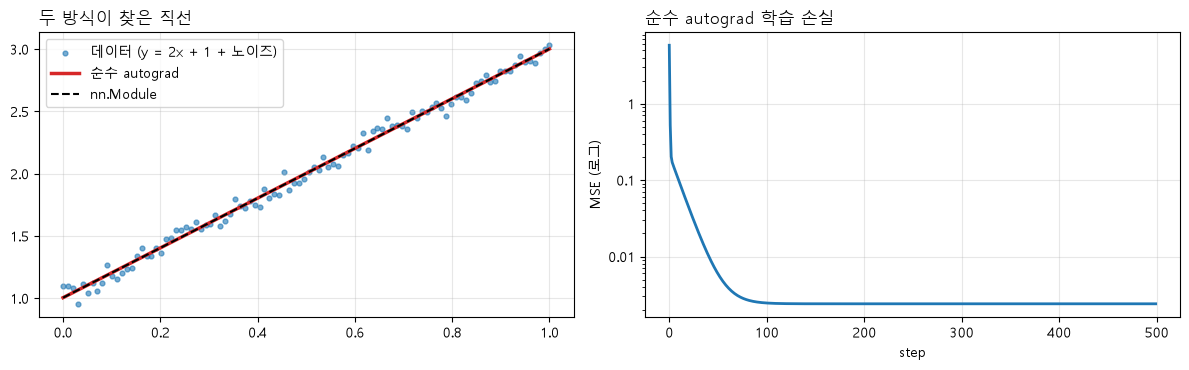

In [14]:
# 두 방식 비교 그래프
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))  # 직선과 손실을 나란히 보기 위해
axes[0].scatter(x2, y2, s=12, alpha=0.6, label="데이터 (y = 2x + 1 + 노이즈)")  # 학습 데이터를 보이기 위해
with torch.no_grad():  # 그래프용 계산이 기록되지 않도록
    axes[0].plot(x2, x2 * w + b, color="tab:red", linewidth=2.5, label="순수 autograd")  # 2-2가 찾은 직선을 그리기 위해
    axes[0].plot(x2, model3(x2), color="black", linestyle="--", linewidth=1.5, label="nn.Module")  # 겹치는지 보이도록 2-3 직선은 점선
axes[0].legend()  # 선을 구분하기 위해
axes[0].set_title("두 방식이 찾은 직선", loc="left")  # 왼쪽 그래프 내용을 알리기 위해
axes[1].plot(losses2, linewidth=2)  # 2-2 손실이 줄어드는 과정을 보기 위해
plain_log(axes[1])  # 손실이 크게 줄어드는 구간까지 한눈에 보기 위해
axes[1].set_xlabel("step")  # 가로축 의미를 알리기 위해
axes[1].set_ylabel("MSE (로그)")  # 세로축 의미를 알리기 위해
axes[1].set_title("순수 autograd 학습 손실", loc="left")  # 오른쪽 그래프 내용을 알리기 위해
plt.tight_layout()  # 칸 간격을 자동으로 맞추기 위해
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
빨간 선 = 검은 점선 : 두 방식이 같은 직선
```

- 초기값은 달라도 **같은 데이터 · 같은 손실 · 같은 학습률**로 충분히 학습 → 같은 최솟값(같은 직선)에 도달
- `nn.Module`과 옵티마이저 = 2-2에서 직접 작성한 순전파 · 갱신 · 기울기 초기화를 **표준화해 감싼 것**

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| plain_log() | 사용자 정의 함수 | 로그 축 + 일반 숫자 눈금 | `plain_log(axes[1])` |
| no_grad() | torch | 그래프용 계산 기록 끄기 | `with torch.no_grad():` |
| subplots() · scatter() · plot() · legend() | matplotlib | 그래프 칸 · 점 · 선 · 범례 | `axes[0].scatter(x2, y2, ...)` |
| with | Python 기본 문법 | 블록 안에서만 기록 끄기 | `with torch.no_grad():` |

### 2-4. 2층 MLP 분류 모델

**한글 요약**

- 초승달 데이터(`make_moons`, 500개)를 분류하는 `2 → 16 → ReLU → 2` 구조 정의
- 출력에 softmax 미적용 (`CrossEntropyLoss`가 내부에서 처리)
- 파라미터 수를 손 계산(82개)과 비교

**실행 흐름**

1. **입력**: make_moons 500개
2. **처리**: 텐서 변환 → MLP 클래스 정의(fc1 → ReLU → fc2) → 모델 생성
3. **저장**: `X` · `y` · `MLP` · `model4`
4. **출력**: 층 구조 · 파라미터 수, 검증 결과

In [15]:
# 데이터 준비
X_np, y_np = make_moons(n_samples=500, noise=0.2, random_state=42)  # 직선으로 나눌 수 없는 데이터로 은닉층 효과를 보기 위해
X = torch.tensor(X_np, dtype=torch.float32)  # nn.Linear가 요구하는 실수형으로 바꾸기 위해
y = torch.tensor(y_np, dtype=torch.long)  # CrossEntropyLoss가 요구하는 정수형 라벨로 바꾸기 위해

# 모델 정의
class MLP(nn.Module):  # 층과 순전파를 묶어 재사용하기 위해
    def __init__(self, hidden=16):  # 은닉 크기를 바꿔 실험할 수 있도록 인자로
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        self.fc1 = nn.Linear(2, hidden)  # 좌표 2개를 은닉 16개로 펼치기 위해
        self.fc2 = nn.Linear(hidden, 2)  # 은닉 16개에서 클래스 2개 점수를 만들기 위해
    def forward(self, x):  # model(x)로 호출할 때 실행되도록
        return self.fc2(F.relu(self.fc1(x)))  # ReLU로 곡선 경계를 만들기 위해 (softmax 없이 logits 출력)

# 모델 확인
model4 = MLP()  # 구조와 파라미터 수를 확인하기 위해
n_params = sum(p.numel() for p in model4.parameters())  # 모든 가중치 · 편향 원소 수를 더하기 위해
print(model4)  # 층 구조를 보기 위해
print(f"파라미터 수: (2×16 + 16) + (16×2 + 2) = {n_params}")  # 손 계산과 비교하기 위해

# 결과 검증
assert model4(X[:5]).shape == (5, 2) and n_params == 82  # 출력 모양과 파라미터 수가 맞는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

MLP(
  (fc1): Linear(in_features=2, out_features=16, bias=True)
  (fc2): Linear(in_features=16, out_features=2, bias=True)
)
파라미터 수: (2×16 + 16) + (16×2 + 2) = 82
✅ 통과


**결과 해설**

```
fc1 Linear(2 → 16) : 가중치 2×16 + 편향 16 = 48
fc2 Linear(16 → 2) : 가중치 16×2 + 편향 2 = 34
파라미터 82개      : 48 + 34, 손 계산과 일치
출력 (5, 2)        : 샘플마다 클래스 2개 점수 (softmax 전 logits)
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| MLP | 사용자 정의 클래스 | 2 → 16 → ReLU → 2 분류 모델 | `model4 = MLP()` |
| make_moons() | sklearn.datasets | 초승달 2클래스 데이터 | `make_moons(n_samples=500, noise=0.2, ...)` |
| Module · Linear() · parameters() · relu() | torch.nn | 부모 클래스 · 선형 층 · 파라미터 · ReLU | `F.relu(self.fc1(x))` |
| tensor(dtype) · numel() | torch | 배열 → 텐서 · 원소 개수 | `torch.tensor(X_np, dtype=torch.float32)` |
| sum() · ( ... for ... ) | Python 내장 함수 · 기본 문법 | 파라미터 합계 | `sum(p.numel() for p in model4.parameters())` |

### 2-5. 학습 루프

**한글 요약**

- **기울기 초기화 → 순전파 → 손실 → 역전파 → 갱신** 5단계로 MLP 300 epoch 학습 (Adam, lr 0.01)
- 손실 곡선과 결정 경계(확률 0.5 선) 시각화로 곡선 경계 학습 확인

**실행 흐름**

1. **입력**: 2-4의 `X` · `y` · `MLP`
2. **처리**: 모델 · 손실 · Adam 준비 → 5단계 학습 루프(300 epoch) → 정확도 → 결정 경계 함수
3. **저장**: `model5` · `losses5` · `plot_boundary`
4. **출력**: 최종 손실 · 정확도, 손실 곡선 · 결정 경계 그래프

최종 손실 0.0670 · 학습 정확도 0.980
✅ 통과


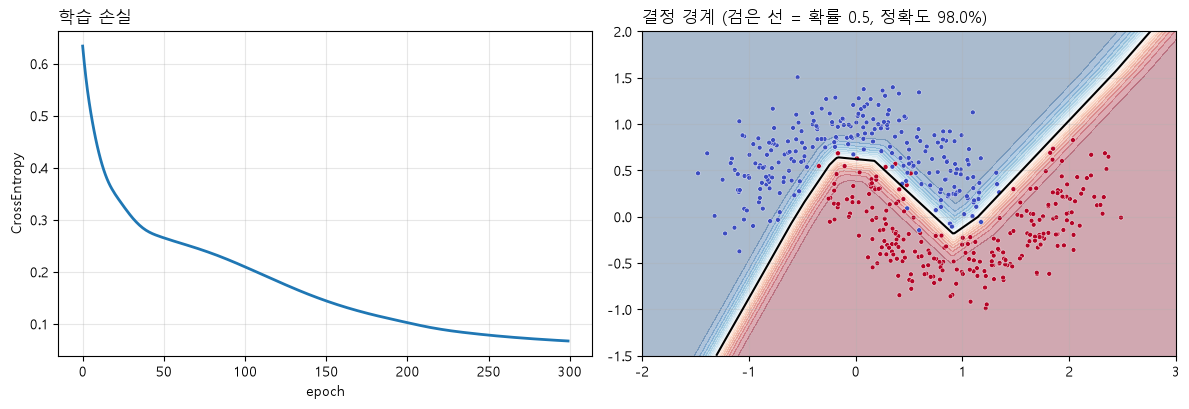

In [16]:
# 학습 준비
torch.manual_seed(42)  # 초기 가중치를 재현하기 위해
model5 = MLP()  # 2-4 구조로 학습하기 위해
criterion = nn.CrossEntropyLoss()  # softmax가 들어 있는 분류 손실을 쓰기 위해
optimizer = torch.optim.Adam(model5.parameters(), lr=0.01)  # 파라미터마다 보폭을 자동 조절하기 위해
losses5 = []  # 학습 과정을 그래프로 보기 위해 손실 기록

# 학습
for epoch in range(300):  # 데이터 전체를 300번 보기 위해
    optimizer.zero_grad()  # 1) 이전 기울기가 누적되지 않도록
    logits = model5(X)  # 2) 500개 전체를 한 번에 순전파하기 위해
    loss = criterion(logits, y)  # 3) 손실을 구하기 위해
    loss.backward()  # 4) 기울기를 구하기 위해
    optimizer.step()  # 5) 가중치를 갱신하기 위해
    losses5.append(loss.item())  # 그래프에 쓰기 위해 숫자만 기록

# 결과 검증
with torch.no_grad():  # 평가에는 기울기가 필요 없으므로
    acc = (model5(X).argmax(dim=1) == y).float().mean().item()  # 점수가 큰 클래스를 예측으로 보고 정답 비율을 구하기 위해
print(f"최종 손실 {losses5[-1]:.4f} · 학습 정확도 {acc:.3f}")  # 학습 결과를 확인하기 위해
assert acc > 0.85  # 곡선 경계를 학습했는지 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

# 결정 경계 함수
def plot_boundary(model, ax, title):  # 2-6 이후에도 같은 방식으로 그리기 위해
    """2차원 평면 전체에 대한 예측을 칠해 결정 경계 표시"""
    xx, yy = np.meshgrid(np.linspace(-2, 3, 300), np.linspace(-1.5, 2, 300))  # 데이터 범위를 300×300 격자로 덮기 위해
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)  # 격자점 9만 개를 모델 입력 (90000, 2)로 만들기 위해
    with torch.no_grad():  # 그래프용 예측이 기록되지 않도록
        prob = torch.softmax(model(grid), dim=1)[:, 1].reshape(xx.shape)  # 클래스 1 확률을 격자 모양으로 되돌리기 위해
    ax.contourf(xx, yy, prob, levels=20, cmap="RdBu_r", alpha=0.35)  # 확률을 색으로 보이기 위해
    ax.contour(xx, yy, prob, levels=[0.5], colors="black", linewidths=1.5)  # 확률 0.5 선 = 결정 경계를 그리기 위해
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap="coolwarm", s=12, edgecolor="white", linewidth=0.3)  # 실제 데이터와 정답 색을 겹쳐 보기 위해
    ax.set_title(title, loc="left")  # 그래프 내용을 알리기 위해

# 손실 · 결정 경계 그래프
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))  # 손실과 경계를 나란히 보기 위해
axes[0].plot(losses5, linewidth=2)  # 손실이 줄어드는 과정을 보기 위해
axes[0].set_xlabel("epoch")  # 가로축 의미를 알리기 위해
axes[0].set_ylabel("CrossEntropy")  # 세로축 의미를 알리기 위해
axes[0].set_title("학습 손실", loc="left")  # 왼쪽 그래프 내용을 알리기 위해
plot_boundary(model5, axes[1], f"결정 경계 (검은 선 = 확률 0.5, 정확도 {acc:.1%})")  # 학습된 모델의 경계를 보기 위해
plt.tight_layout()  # 칸 간격을 자동으로 맞추기 위해
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
최종 손실 0.0670 · 정확도 98.0% : 500개 중 490개 정답
결정 경계                       : 은닉층 + ReLU로 직선이 아닌 곡선 경계 학습
```

- 은닉층 없이 선형 층 하나만 쓰면 직선 경계밖에 만들 수 없어 두 초승달을 깔끔하게 나눌 수 없음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| plot_boundary() | 사용자 정의 함수 | 결정 경계 그리기 | `plot_boundary(model5, axes[1], ...)` |
| CrossEntropyLoss() · Adam() · zero_grad() · step() | torch.nn · torch.optim | 분류 손실 · 적응형 옵티마이저 · 초기화 · 갱신 | `torch.optim.Adam(model5.parameters(), lr=0.01)` |
| softmax() · argmax() · float() · mean() | torch | 확률 · 예측 클래스 · 정확도 | `(model5(X).argmax(dim=1) == y).float().mean()` |
| meshgrid() · c_[] · ravel() | numpy | 격자 · 열 결합 · 펼치기 | `np.c_[xx.ravel(), yy.ravel()]` |
| contourf() · contour() · scatter() | matplotlib | 확률 색칠 · 0.5 경계선 · 데이터 점 | `ax.contour(..., levels=[0.5])` |

### 2-6. DataLoader로 미니배치 학습

**한글 요약**

- 500개를 한 번에 넣지 않고 64개씩 나눠 학습 → 한 epoch에 8번 갱신 (500 / 64 → 8개 배치)
- 2-5 전체 배치와 **같은 갱신 횟수** · **같은 계산량** 두 기준으로 비교

**실행 흐름**

1. **입력**: `X` · `y` (2-5와 같은 데이터)
2. **처리**: TensorDataset → DataLoader 64개씩(매 epoch 섞기) → 배치별 학습(100 epoch) → 두 기준 비교
3. **저장**: `model6` · `losses6`
4. **출력**: 배치 수 · 손실 · 정확도, 갱신 횟수 기준 손실 곡선, 비교 문장

배치 수 8 · 최종 손실 0.0586 · 학습 정확도 0.982
✅ 통과


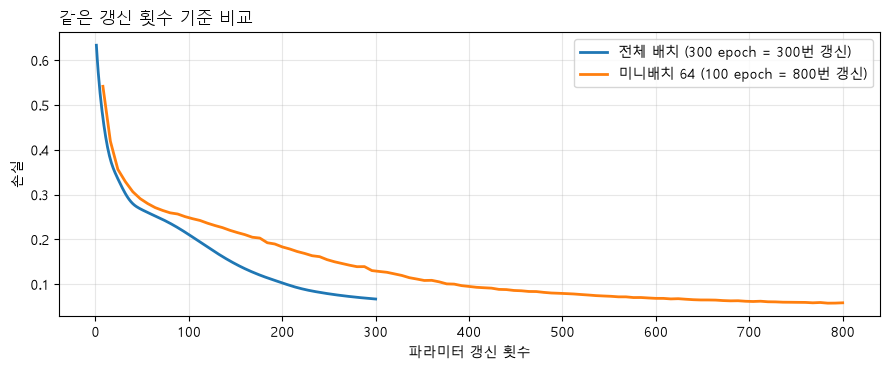

300번 갱신 시점 손실 · 전체 배치 0.0670 vs 미니배치 0.1305
계산량(샘플 처리 수) · 전체 배치 300 epoch = 150,000 → 손실 0.0670 | 미니배치 100 epoch = 50,000 → 손실 0.0586


In [17]:
# 데이터 준비
dataset = TensorDataset(X, y)  # 입력과 라벨을 샘플 단위로 함께 꺼내기 위해
loader = DataLoader(dataset, batch_size=64, shuffle=True)  # 64개씩 나누고 매 epoch 순서를 섞어 학습 편향을 줄이기 위해

# 학습 준비
torch.manual_seed(42)  # 초기 가중치를 재현하기 위해
model6 = MLP()  # 2-5와 같은 구조로 비교하기 위해
criterion = nn.CrossEntropyLoss()  # 2-5와 같은 손실을 쓰기 위해
optimizer = torch.optim.Adam(model6.parameters(), lr=0.01)  # 2-5와 같은 옵티마이저 · 학습률로 비교하기 위해
losses6 = []  # epoch별 평균 손실을 기록하기 위해

# 학습
for epoch in range(100):  # 계산량을 2-5의 1/3로 맞추기 위해 100 epoch
    epoch_loss = 0.0  # epoch 전체 손실을 더하기 위해
    for xb, yb in loader:  # 배치 8개를 차례로 학습하기 위해
        optimizer.zero_grad()  # 배치마다 기울기를 초기화하기 위해
        logits = model6(xb)  # 배치 단위로 순전파하기 위해
        loss = criterion(logits, yb)  # 배치 평균 손실을 구하기 위해
        loss.backward()  # 기울기를 구하기 위해
        optimizer.step()  # 배치마다 갱신하기 위해
        epoch_loss += loss.item() * len(xb)  # 마지막 배치(52개) 크기까지 반영해 평균을 합계로 바꾸기 위해
    losses6.append(epoch_loss / len(dataset))  # 2-5와 비교할 수 있도록 샘플 1개당 평균 손실로

# 결과 검증
with torch.no_grad():  # 평가에는 기울기가 필요 없으므로
    acc6 = (model6(X).argmax(dim=1) == y).float().mean().item()  # 전체 500개 정확도를 구하기 위해
print(f"배치 수 {len(loader)} · 최종 손실 {losses6[-1]:.4f} · 학습 정확도 {acc6:.3f}")  # 학습 결과를 확인하기 위해
assert len(dataset) == 500 and loader.batch_size == 64 and len(loader) == 8 and acc6 > 0.85  # 데이터 수 · 배치 설정 · 성능을 확인하기 위해
print("✅ 통과")  # 검증을 통과했음을 보이기 위해

# 갱신 횟수 기준 비교 그래프
fig, ax = plt.subplots(figsize=(9, 3.8))  # 두 방식을 한 그래프에 겹치기 위해
updates5 = np.arange(1, len(losses5) + 1)  # 전체 배치는 epoch당 1번 갱신
updates6 = np.arange(1, len(losses6) + 1) * len(loader)  # 미니배치는 epoch당 8번 갱신
ax.plot(updates5, losses5, label="전체 배치 (300 epoch = 300번 갱신)", linewidth=2)  # 2-5 손실을 갱신 횟수 축에 놓기 위해
ax.plot(updates6, losses6, label="미니배치 64 (100 epoch = 800번 갱신)", linewidth=2)  # 2-6 손실을 같은 축에 놓기 위해
ax.set_xlabel("파라미터 갱신 횟수")  # epoch 대신 갱신 횟수로 맞춰 비교하기 위해
ax.set_ylabel("손실")  # 세로축 의미를 알리기 위해
ax.set_title("같은 갱신 횟수 기준 비교", loc="left")  # 비교 기준을 알리기 위해
ax.legend()  # 선을 구분하기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그래프를 출력하기 위해

# 같은 갱신 · 같은 계산량 비교
print(f"300번 갱신 시점 손실 · 전체 배치 {losses5[299]:.4f} vs 미니배치 {losses6[300 // len(loader) - 1]:.4f}")  # 같은 갱신 횟수로 비교하기 위해 (미니배치 37 epoch = 296번 갱신)
print(f"계산량(샘플 처리 수) · 전체 배치 300 epoch = {300 * 500:,} → 손실 {losses5[-1]:.4f} | 미니배치 100 epoch = {100 * 500:,} → 손실 {losses6[-1]:.4f}")  # 처리한 샘플 수 기준으로 비교하기 위해

**결과 해설**

```
배치 수 8                            : 64 × 7 = 448개 + 마지막 배치 52개
손실 0.0586 · 정확도 98.2%           : 전체 배치(2-5, 98.0%)와 비슷한 성능
약 300번 갱신 시점 0.0670 vs 0.1305 : 전체 배치가 더 낮음 (미니배치는 37 epoch = 296번 갱신 시점)
같은 계산량 기준                     : 미니배치 50,000개 처리 → 0.0586 < 전체 배치 150,000개 처리 → 0.0670
```

- **같은 갱신 횟수**: 전체 배치 우세. 미니배치 기울기는 64개로 추정한 값이라 잡음 포함
- **같은 계산량**: 미니배치 우세. 데이터를 1/3만 처리하고도 더 낮은 손실 → 갱신 한 번이 싸서 같은 계산으로 더 자주 갱신 가능

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| TensorDataset() · DataLoader() · batch_size | torch.utils.data | 샘플 단위 묶기 · 배치 분할 · 크기 | `DataLoader(dataset, batch_size=64, shuffle=True)` |
| Adam() · zero_grad() · step() | torch.optim | 옵티마이저 · 초기화 · 갱신 | `optimizer.step()` |
| arange() | numpy | 갱신 횟수 축 | `np.arange(1, len(losses6) + 1) * len(loader)` |
| subplots() · plot() · legend() | matplotlib | 그래프 · 손실 곡선 · 범례 | `ax.plot(updates5, losses5, ...)` |
| for (중첩) · += · // | Python 기본 문법 | epoch · 배치 이중 반복 · 누적 · 정수 나눗셈 | `for xb, yb in loader:` · `300 // len(loader)` |

### 2-7. 옵티마이저와 학습률 비교 · 학습

**한글 요약**

같은 모델 · 같은 초기값(seed 0)에서 `SGD 0.01` · `SGD 0.5` · `SGD 10.0` · `Adam 0.01`로 200 epoch 학습.

**실행 흐름**

1. **입력**: `X` · `y`, 옵티마이저 설정 4개
2. **처리**: 학습 함수(seed 0 고정 → 같은 초기값) → 4개 설정으로 각각 200 epoch 학습
3. **저장**: `results` · `accuracies` · `models`
4. **출력**: 없음 (assert로 200 epoch 완료 확인)

In [18]:
# 학습 함수
def train_with(optimizer_fn, epochs=200):  # 옵티마이저만 바꾸고 나머지는 똑같이 학습하기 위해
    """같은 초기값(seed 0)의 MLP를 주어진 옵티마이저로 학습, 손실 기록 · 정확도 · 모델 반환"""
    torch.manual_seed(0)  # 설정마다 같은 초기 가중치에서 출발하도록
    model = MLP()  # 2-4 구조로 공정하게 비교하기 위해
    criterion = nn.CrossEntropyLoss()  # 같은 손실로 비교하기 위해
    optimizer = optimizer_fn(model.parameters())  # 설정별 옵티마이저를 만들기 위해
    losses = []  # 손실 곡선을 그리기 위해
    for _ in range(epochs):  # 모든 설정을 같은 횟수로 학습하기 위해
        optimizer.zero_grad()  # 이전 기울기가 누적되지 않도록
        loss = criterion(model(X), y)  # 순전파와 손실을 한 번에 계산하기 위해
        loss.backward()  # 기울기를 구하기 위해
        optimizer.step()  # 설정별 방식으로 갱신하기 위해
        losses.append(loss.item())  # 손실을 기록하기 위해
    with torch.no_grad():  # 평가에는 기울기가 필요 없으므로
        accuracy = (model(X).argmax(1) == y).float().mean().item()  # 학습 데이터 정확도를 구하기 위해
    return losses, accuracy, model  # 그래프 · 표 · 죽은 ReLU 확인에 모두 쓰기 위해

# 설정별 학습
settings = {
    "SGD lr=0.01": lambda p: torch.optim.SGD(p, lr=0.01),  # 보폭이 작을 때를 보기 위해
    "SGD lr=0.5": lambda p: torch.optim.SGD(p, lr=0.5),  # 보폭이 적당할 때를 보기 위해
    "SGD lr=10.0": lambda p: torch.optim.SGD(p, lr=10.0),  # 보폭이 너무 클 때를 보기 위해
    "Adam lr=0.01": lambda p: torch.optim.Adam(p, lr=0.01),  # SGD 0.01과 같은 학습률에서 보폭 자동 조절 효과를 보기 위해
}
results, accuracies, models = {}, {}, {}  # 설정 이름별 결과를 모으기 위해
for name, fn in settings.items():  # 설정을 하나씩 학습하기 위해
    results[name], accuracies[name], models[name] = train_with(fn)  # 손실 · 정확도 · 모델을 한 번에 저장하기 위해
assert all(len(v) == 200 for v in results.values())  # 모든 설정이 200 epoch를 마쳤는지 확인하기 위해

**결과 해설**

```
출력 없음 : 4개 설정 학습 완료 (assert 통과), 다음 두 셀에서 손실 곡선과 비교표
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_with() | 사용자 정의 함수 | 설정별 학습 · 결과 반환 | `train_with(fn)` |
| SGD() · Adam() | torch.optim | 비교 대상 옵티마이저 | `torch.optim.SGD(p, lr=10.0)` |
| manual_seed() · no_grad() | torch | 같은 초기값 · 기록 끄기 | `torch.manual_seed(0)` |
| all() · len() · range() | Python 내장 함수 | 모두 True · 개수 · 반복 | `all(len(v) == 200 for v in results.values())` |
| lambda · 여러 변수 동시 대입 | Python 기본 문법 | 옵티마이저 생성 함수 · 결과 3개 저장 | `lambda p: torch.optim.SGD(p, lr=0.01)` |

### 2-7. 옵티마이저와 학습률 비교 · 손실 곡선

**한글 요약**

4개 설정의 손실 곡선을 0~2 구간(일반 축)과 전체 범위(로그 축)로 비교.

**실행 흐름**

1. **입력**: `results` (설정별 손실 기록)
2. **처리**: 같은 기록을 일반 축 · 로그 축 두 칸에 그리기
3. **저장**: 없음
4. **출력**: 손실 곡선 그래프 2칸

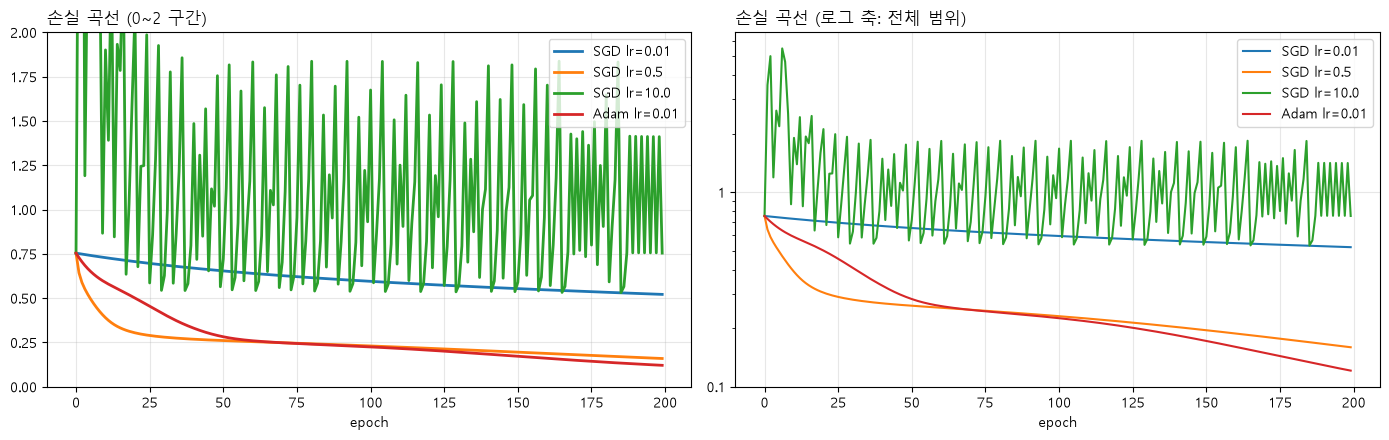

In [19]:
# 손실 곡선 그래프
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))  # 확대 구간과 전체 범위를 나란히 보기 위해
for name, losses in results.items():  # 설정마다 선 하나씩 그리기 위해
    axes[0].plot(losses, label=name, linewidth=2)  # 0~2 구간에서 차이를 보기 위해
    axes[1].plot(losses, label=name, linewidth=1.5)  # 같은 기록을 로그 축으로 보기 위해
axes[0].set_ylim(0, 2)  # lr=10의 큰 값을 잘라 나머지 설정의 차이를 키워 보기 위해
axes[0].set_title("손실 곡선 (0~2 구간)", loc="left")  # 왼쪽 그래프 범위를 알리기 위해
plain_log(axes[1])  # 0.1 ~ 5 범위를 한 그래프에 담기 위해
axes[1].set_title("손실 곡선 (로그 축: 전체 범위)", loc="left")  # 오른쪽 그래프 범위를 알리기 위해
for ax in axes:  # 두 칸에 같은 설정을 하기 위해
    ax.set_xlabel("epoch")  # 가로축 의미를 알리기 위해
    ax.legend()  # 설정별 선을 구분하기 위해
plt.tight_layout()  # 칸 간격을 자동으로 맞추기 위해
plt.show()  # 그래프를 출력하기 위해

**결과 해설**

```
SGD 0.01  : 손실이 천천히 줄어 200 epoch 뒤에도 0.5 근처
SGD 0.5   : 처음 25 epoch에 가장 빠르게 감소한 뒤 완만해짐
SGD 10.0  : 0.5~5.5 사이를 오가며 진동 (로그 축에서 전체 범위 확인)
Adam 0.01 : 꾸준히 감소, 75 epoch 무렵 SGD 0.5보다 낮아져 가장 낮은 손실에 도달
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| plain_log() | 사용자 정의 함수 | 로그 축 + 일반 숫자 눈금 | `plain_log(axes[1])` |
| subplots() · plot() · set_ylim() · legend() | matplotlib | 그래프 칸 · 곡선 · 세로 범위 · 범례 | `axes[0].set_ylim(0, 2)` |
| items() | Python dict | 설정 이름 · 손실 기록 쌍 | `results.items()` |
| for | Python 기본 문법 | 설정 · 칸 반복 | `for ax in axes:` |

### 2-7. 옵티마이저와 학습률 비교 · 비교표와 원인 확인

**한글 요약**

- 수렴 속도 · 안정성(마지막 50 epoch 손실 표준편차) · 정확도를 한 표로 비교
- `SGD 10.0` 진동 원인 확인용 죽은 ReLU 뉴런 수 · 초반 손실 확인

**실행 흐름**

1. **입력**: `results` · `accuracies` · `models`
2. **처리**: 최종 · 최소 · 최대 손실, 0.3 도달 epoch, 표준편차 → 은닉층 출력으로 죽은 ReLU 수 → lr=10 초반 손실
3. **저장**: `summary` · `dead`
4. **출력**: 설정별 비교표, 죽은 ReLU 수, 초반 손실

In [20]:
# 설정별 비교 표
rows = []  # 설정별 결과를 한 표로 모으기 위해
for name, losses in results.items():  # 설정마다 통계를 계산하기 위해
    arr = np.array(losses)  # 통계 함수를 쓰기 위해 배열로
    reach = np.where(arr < 0.3)[0]  # 수렴 속도를 재기 위해 손실 0.3 미만인 epoch 위치를 찾음
    rows.append({"설정": name, "최종 손실": arr[-1], "최소 손실": arr.min(), "최대 손실": arr.max(),  # 수렴 수준과 진동 폭을 보기 위해
                 "손실 0.3 도달 epoch": int(reach[0]) + 1 if len(reach) else "도달 못함",  # 1부터 세고, 못 닿으면 그렇게 표시하기 위해
                 "마지막 50 epoch 손실 표준편차": arr[-50:].std(), "최종 정확도": accuracies[name]})  # 안정성과 성능을 함께 보기 위해
summary = pd.DataFrame(rows).set_index("설정")  # 설정 이름을 행 이름으로 보기 위해
display(summary.style.format({"최종 손실": "{:.4f}", "최소 손실": "{:.4f}", "최대 손실": "{:.3g}",
                              "마지막 50 epoch 손실 표준편차": "{:.4f}", "최종 정확도": "{:.1%}"}))  # 자릿수 · 백분율로 읽기 쉽게 출력하기 위해

# 죽은 ReLU · 초반 손실 확인
dead = {}  # 설정별 죽은 뉴런 수를 모으기 위해
with torch.no_grad():  # 확인용 계산이 기록되지 않도록
    for name, model in models.items():  # 학습된 모델마다 확인하기 위해
        hidden = F.relu(model.fc1(X))  # 은닉층 출력 (500, 16)을 보기 위해
        dead[name] = int((hidden.max(dim=0).values == 0).sum())  # 500개 입력 모두에서 0인 뉴런 = 죽은 ReLU를 세기 위해
arr10 = np.array(results["SGD lr=10.0"])  # 진동한 설정의 손실을 자세히 보기 위해
print("죽은 ReLU 뉴런 수 (16개 중):", dead)  # 설정별로 비교하기 위해
print("SGD lr=10.0 처음 10 epoch 손실:", np.round(arr10[:10], 3).tolist())  # 첫 갱신부터 손실이 튀는지 보기 위해

,최종 손실,최소 손실,최대 손실,손실 0.3 도달 epoch,마지막 50 epoch 손실 표준편차,최종 정확도
설정,,,,,,
SGD lr=0.01,0.5211,0.5211,0.754,도달 못함,0.0095,83.4%
SGD lr=0.5,0.1593,0.1593,0.754,23,0.0105,93.6%
SGD lr=10.0,0.7541,0.5312,5.48,도달 못함,0.4001,70.4%
Adam lr=0.01,0.1208,0.1208,0.754,47,0.0151,96.0%


죽은 ReLU 뉴런 수 (16개 중): {'SGD lr=0.01': 2, 'SGD lr=0.5': 2, 'SGD lr=10.0': 9, 'Adam lr=0.01': 5}
SGD lr=10.0 처음 10 epoch 손실: [0.754, 3.554, 5.003, 1.191, 2.624, 2.181, 5.481, 4.677, 2.527, 0.866]


**결과 해설**

```
SGD 0.01  : 최종 손실 0.5211 · 정확도 83.4%, 보폭이 작아 0.3 도달 못함
SGD 0.5   : 최종 손실 0.1593 · 정확도 93.6%, 0.3 도달 23 epoch로 가장 빠름
SGD 10.0  : 최대 손실 5.48 · 표준편차 0.4001, 진동하며 정확도 70.4%
Adam 0.01 : 최종 손실 0.1208 · 정확도 96.0%로 최고, 0.3 도달 47 epoch
죽은 ReLU : SGD 10.0 9개 > Adam 5개 > SGD 0.01 · 0.5 2개 (16개 중)
```

- 모든 정확도는 **학습 데이터 기준** (별도 검증 데이터 없음) → 일반화 성능이 아닌 학습 정도 비교

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| array() · where() · std() · round() · tolist() | numpy | 배열 · 조건 위치 · 표준편차 · 반올림 · 목록 | `np.where(arr < 0.3)[0]` |
| DataFrame() · set_index() · style.format() | pandas | 결과 표 · 행 이름 · 서식 | `pd.DataFrame(rows).set_index("설정")` |
| relu() · max(dim=0).values · sum() | torch | 은닉층 출력 · 뉴런별 최댓값 · 개수 | `hidden.max(dim=0).values == 0` |
| display() | IPython.display | 셀 중간 표 출력 | `display(summary.style.format({...}))` |
| 조건 표현식 · int() | Python 기본 문법 · 내장 함수 | 도달 여부에 따른 값 · 정수 변환 | `int(reach[0]) + 1 if len(reach) else "도달 못함"` |

---
## 3. 마무리

### 3-1. 옵티마이저 비교 서술: 측정값으로 답하기

**1. 가장 빠르고 안정적으로 수렴한 설정은?**
- **200 epoch 결과 기준으로는 `Adam lr=0.01`**: 최종 손실 0.121로 가장 낮고, 정확도도 96.0%로 가장 높음, 마지막 50 epoch 손실 표준편차 0.015로 안정적
- **초반 속도만 보면 `SGD lr=0.5`가 더 빠름**: 손실 0.3 도달 23 epoch, Adam은 47 epoch → 학습률이 잘 맞으면 SGD도 빠르지만, 끝까지 가면 Adam이 더 낮은 손실에 도달
- `SGD lr=0.01`은 보폭이 너무 작아 200 epoch 동안 손실 0.52에 머묾

**2. `SGD lr=10.0`에서는 무슨 일이 일어났나?**
- **진동하며 수렴 실패**: 첫 갱신에서 손실 0.754 → 3.55로 오히려 증가, 이후 0.5~5.5 사이를 오갔고 마지막 50 epoch 표준편차 0.40으로 다른 설정(0.0095~0.015)보다 25배 이상 큼, 최종 정확도 70.4%
- **원인은 overshooting**: 갱신량 = `학습률 × 기울기`. 학습률이 너무 크면 최솟값을 **훌쩍 건너뛰어** 반대편의 더 높은 지점에 떨어지고, 이것이 반복됨
- **부작용**: 큰 갱신이 은닉층 가중치를 크게 흔들어 16개 뉴런 중 9개가 모든 입력에 0만 출력하는 **죽은 ReLU**가 됨(SGD 0.5는 2개). 죽은 뉴런은 기울기가 0이라 다시 살아나지 못함

**3. Adam은 SGD와 무엇이 다른가?**

| | SGD | Adam |
| :-- | :-- | :-- |
| 이동 방향 | 현재 기울기만 사용 | **모멘텀**: 기울기의 지수이동평균(1차 모멘트), 일관된 방향은 가속 · 지그재그 진동은 상쇄 |
| 보폭 | 모든 파라미터에 같은 고정 학습률 | **RMSProp**: 기울기 제곱의 지수이동평균(2차 모멘트)으로 나눠 파라미터마다 보폭 자동 조절 |
| 초기 보정 | 없음 | 두 평균이 0에서 시작하는 편향을 보정 |

- **같은 학습률 0.01**에서도 SGD는 손실 0.52, Adam은 0.12까지 감소 → Adam은 학습률 선택에 덜 민감
- 다만 학습률이 잘 맞는 SGD가 초반에 더 빠를 수 있어, 어느 쪽이 항상 낫다고 할 수는 없음

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1. 텐서 기초** | 생성 · 인덱싱 · 모양 · 타입 · 이어붙이기 · 행렬곱 · autograd · 활성화 · device | 모든 문제 assert 통과, autograd 7.0 = 손 계산 7 |
| **2-1 ~ 2-3. 회귀** | 손실 함수 직접 계산, 순수 autograd vs nn.Module | 두 방식 모두 w 1.997 · b 1.004 |
| **2-4 ~ 2-6. 분류** | 2층 MLP, 5단계 학습 루프, 미니배치 | 정확도 98.0%, 계산량 1/3로 손실 0.0586 |
| **2-7. 옵티마이저** | SGD 3가지 학습률 vs Adam | Adam 0.121 · 96.0%, SGD 10.0 진동 · 죽은 ReLU 9개 |